<a href="https://colab.research.google.com/github/smgrubb/uwaterloosmgrubb/blob/main/FiniteDifferenceMethod.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Finite difference method solver

This is a python programme I (Shintaro) wrote so that all of you can use the finite difference method to solve 2nd order linear boundary value problems. I will work with placeholder functions, but hopefully you can see how to modify the code to solve *any* linear boundary value problem.

General BVP: $$y''(x) + p(x)y'(x) + q(x)y(x) = f(x),$$
$$y(a) = A, y(b) = B.$$ There is no catch-all analytic method to solve this. However, the finite difference method converts this linear ODE into a "linear equation" (in the sense of linear algebra).


In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np

# Initializing everything
In any modification of the problem (boundary values, equation, stepsize etc) you will only ever have to modify this section of the program. (You should still read all of the code though!)

Step size $h = (b-a)/N,$ where $N$ is the number of steps. **Warning: $N$ must be at least 3 for the code to work.** As an example, we're working with boundary values $y(3)=5$ and $y(8)=4$.

In [ ]:
a = 3 #Declare leftmost x value
b = 8 #Declare rightmost x value
A = 5 #Declare y(a)
B = 4 #Declare y(b)
N = 100 #Declare step count.
h = (b-a)/N #Calculate step size


In [ ]:
X = [a+n*h for n in range(N+1)] #Creating list of x_0, x_1, ..., x_N

#We must also choose functions p(x), q(x), and f(x). As an example, I will set p(x) = 0, q(x) = x, and f(x) = x^2. What we really must do is create lists which contain the values [p(x_0), p(x_1), ..., p(x_N)] etc.

P = [0 for x_n in X] #Creating list of p(x_n) values
Q = [x_n for x_n in X] #Creating list of q(x_n) values
F = [x_n**2 for x_n in X] #Creating list of f(x_n) values


#Rewriting the BVP as a difference equation


We now rewrite our differential equation as a difference equation:
$$y''(x) + p(x)y'(x) + q(x)y(x) = f(x)$$
...becomes...
$$\frac{y(x+h)-2y(x)+y(x-h)}{h^2} + p(x)\frac{y(x+h)-y(x-h)}{2h} + q(x)y(x) = f(x)$$
Next, we discretize the domain (replace $x$ with $x_n$, and $y(x_n)$ with $y_n$, etc).
$$\frac{y_{n+1} - 2y_n + y_{n-1}}{h^2} + p_n\frac{y_{n+1}-y_{n-1}}{2h} + q_ny_n = f_n.$$
Rearrange to group $y$ terms:
$$\left(\frac{1}{h^2} - \frac{p_n}{2h}\right)y_{n-1} + \left(-\frac{2}{h^2} + q_n\right)y_n + \left(\frac{1}{h^2} + \frac{p_n}{2h}\right)y_{n+1} = f_n.$$

We now have our system of equations, where $n$ varies from 1 to $N-1$. ($n=0$ and $n=N$ are irrelevant, because we already know the value of $y(a)$ and $y(b)$.) However, the two edge cases ($n=1$ and $n=N-1$) also involve $y_0$ and $y_N$ in their equations, so we substitute boundary conditions:


$$\left(-\frac{2}{h^2} + q_1\right)y_1 + \left(\frac{1}{h^2} + \frac{p_1}{2h}\right)y_2 = f_1 - \left(\frac{1}{h^2} - \frac{p_1}{2h}\right)A$$

$$\left(\frac{1}{h^2} - \frac{p_{N-1}}{2h}\right)y_{N-2} + \left(-\frac{2}{h^2} + q_{N-1}\right)y_{N-1} = f_{N-1} - \left(\frac{1}{h^2} + \frac{p_{N-1}}{2h}\right)B$$

This now gives the full linear system of equations. We are ready to express this in python (rather than as a comment).


#The linear equation (finite difference method)

The BVP will be expressed as a linear equation $MY=G$, where $M$ is the matrix of "coefficients" from the linear system of difference equations above, $Y$ is a vector containing the "solution" $(y_1,...,y_{N-1})$, and $G$ is a vector containing the "right hand side" of the linear system above: $(f_1 - (1/h^2 - p_1/2h)A, f_2, f_3, ...)$ etc.

In [ ]:
M = [[0 for n in range(N-1)] for m in range(N-1)] #Initializing (N-1)x(N-1) matrix of 0s
G = [None]*(N-1) #Initializing list of f_n values for the purpose of the linear equation.

#Hardcoding the edge cases. Note that for indexing the lists M and G, there is an off-by-one adjustment (because these lists all start at n=1 instead of n=0.)
M[0][0] = -2/(h**2) + Q[1]
M[0][1] = 1/(h**2) + P[1]/(2*h)
M[N-2][N-3] = 1/(h**2) - P[N-1]/(2*h)
M[N-2][N-2] = -2/(h**2) + Q[N-1]
G[0] = F[1] - (1/(h**2) - P[1]/(2*h))*A
G[N-2] = F[N-1] - (1/(h**2) + P[N-1]/(2*h))*B

#Iteratively coding the non-edge cases.
for n in range(N-3):
    G[n+1] = F[n+2]
    M[n+1][n] = 1/(h**2) - P[n+2]/(2*h)
    M[n+1][n+1] = -2/(h**2) + Q[n+2]
    M[n+1][n+2] = 1/(h**2) + P[n+2]/(2*h)


Print $M$ and $G$ just to check that they look correct.



In [ ]:
print(M)

[[-796.9499999999999, 399.99999999999994, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [399.99999999999994, -796.8999999999999, 399.99999999999994, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 399.99999999999994, -796.8499999999999, 399.99999999999994, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [ ]:
print(G)

[-1990.6974999999998, 9.610000000000001, 9.9225, 10.240000000000002, 10.5625, 10.889999999999999, 11.2225, 11.559999999999999, 11.902500000000002, 12.25, 12.6025, 12.96, 13.3225, 13.690000000000001, 14.0625, 14.44, 14.822500000000002, 15.209999999999999, 15.602500000000001, 16.0, 16.4025, 16.81, 17.222500000000004, 17.64, 18.0625, 18.49, 18.922499999999996, 19.360000000000003, 19.802500000000002, 20.25, 20.702499999999997, 21.159999999999997, 21.622500000000002, 22.090000000000003, 22.5625, 23.04, 23.522499999999997, 24.010000000000005, 24.5025, 25.0, 25.50250000000001, 26.009999999999998, 26.522500000000004, 27.040000000000003, 27.5625, 28.090000000000007, 28.622499999999995, 29.160000000000004, 29.7025, 30.25, 30.80250000000001, 31.359999999999996, 31.922500000000003, 32.49, 33.0625, 33.64000000000001, 34.2225, 34.81, 35.4025, 36.0, 36.602500000000006, 37.209999999999994, 37.822500000000005, 38.440000000000005, 39.0625, 39.69000000000001, 40.3225, 40.96000000000001, 41.6025, 42.25, 4

The one line that does everything!

In [ ]:
Y = np.linalg.solve(M,G)

The above line of code computes $y_1$ through to $y_{N-1}$. For completeness, we should append $y_0$ and $y_N$ to the list. We can print the list, but we can also plot it.

[5, 5.721125863985758, 6.421884393258625, 7.096898318483737, 7.7408304194507895, 8.348435877062235, 8.91461654317255, 9.434476622801691, 9.903379210714869, 10.317003075336968, 10.671399038434286, 10.963045259945305, 11.188900704774314, 11.346456043260352, 11.43378122035164, 11.449568921154675, 11.393173163321883, 11.264642260437535, 11.064745425796486, 10.794992323253926, 10.457644921519233, 10.05572107056935, 9.592989293779953, 9.073954376729311, 8.503833433020104, 7.888522238264183, 7.234551744726705, 6.549034819933416, 5.839603391473353, 5.114336325707082, 4.381678518317321, 3.650351827596489, 2.9292586348367475, 2.2273789677763833, 1.5536622702156184, 0.91691504097982, 0.32568569563238625, -0.21185187806263603, -0.6880144977361489, -1.095723939812394, -1.4286175481334602, -1.6811534371028583, -1.8487085139288328, -1.9276675572022148, -1.9155016306766182, -1.8108341829522252, -1.6134932865765843, -1.3245486041538037, -0.9463318341504657, -0.4824395843860963, 0.0622821547155337, 0.68

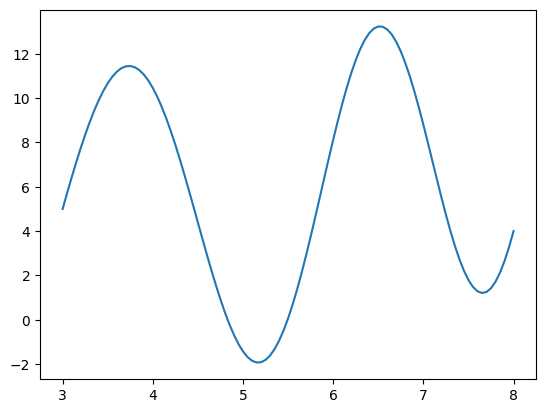

In [ ]:
Y = [A] + Y.tolist() + [B]

print(Y)

plt.plot(X,Y)
plt.show()
